In [2]:
import pycalphad
print(pycalphad.__version__)

0.11.2


In [3]:
from pycalphad import Database, equilibrium
db = Database('../data/steel1.TDB')
print(sorted(db.elements))
print(sorted(db.phases.keys()))

['/-', 'C', 'CR', 'FE', 'MO', 'SI', 'V', 'VA']
['BCC_A2', 'CBCC_A12', 'CEMENTITE', 'CHI_A12', 'CR1SI1', 'CR2VC2', 'CR3SI', 'CR5SI3', 'CRSI2', 'CUB_A13', 'DIAMOND_A4', 'FCC_A1', 'FE1SI1', 'FE2SI', 'FE4N', 'FE5SI3', 'FE8SI2C', 'FECN_CHI', 'FESI2_H', 'FESI2_L', 'GRAPHITE', 'HCP_A3', 'KSI_CARBIDE', 'LAVES_PHASE', 'LIQUID', 'M23C6', 'M3C2', 'M3SI', 'M5C2', 'M6C', 'M7C3', 'MC_ETA', 'MC_SHP', 'MONI_DELTA', 'MU_PHASE', 'P_PHASE', 'R_PHASE', 'SIC', 'SIGMA', 'V3C2']


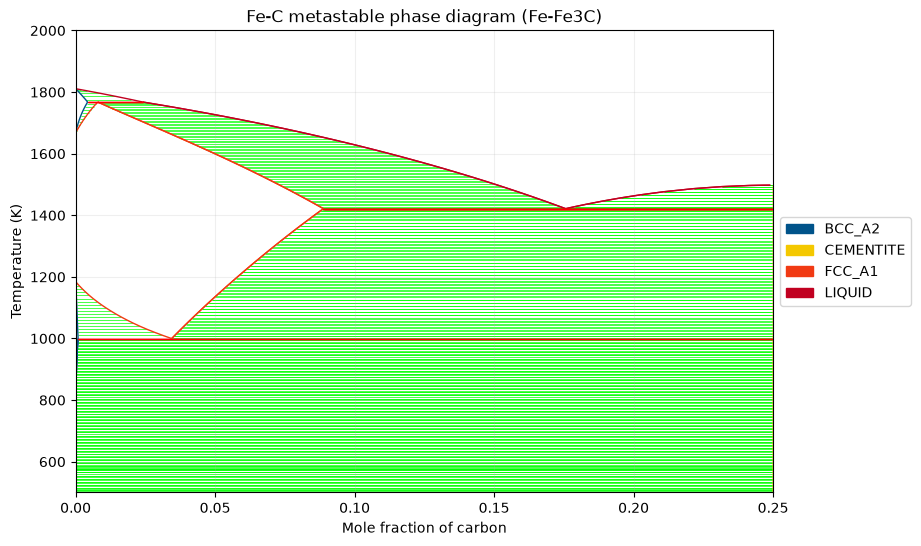

In [4]:
import matplotlib.pyplot as plt
from pycalphad import binplot, variables as v

comps = ['FE', 'C', 'VA']
phases = ['LIQUID', 'BCC_A2', 'FCC_A1', 'CEMENTITE']

fig, ax = plt.subplots(figsize=(9, 6))
binplot(db, comps, phases,
        {v.X('C'): (0, 0.25, 0.01), v.T: (500, 2000, 10), v.P: 101325, v.N: 1},
        plot_kwargs={'ax': ax},
        timelines=False) 
ax.set_title('Fe-C metastable phase diagram (Fe-Fe3C)')
ax.set_xlabel('Mole fraction of carbon')
ax.set_ylabel('Temperature (K)')
ax.grid(alpha=0.2)
plt.show()

In [5]:
#wt% to mole fraction conversion
def wtC_to_xC(wt_c):
    """Convert wt% C to mole fraction C in Fe-C alloy."""
    M_C, M_Fe = 12.011, 55.845
    n_c = wt_c / M_C
    n_fe = (100 - wt_c)/M_Fe
    return n_c / (n_c + n_fe)

def xC_to_wtc(x_c):
    """Convert mole fraction C to wt% C."""
    M_C, M_Fe = 12.011, 55.845
    return 100 * x_c * M_C / (x_c * M_C + (1 - x_c) * M_Fe)

print(wtC_to_xC(0.77)) #eutectoid
print(wtC_to_xC(4.3)) #eutectic

0.03482250806732187
0.17280935864216265


A1 = 730 degC,  A3 = 780 degC


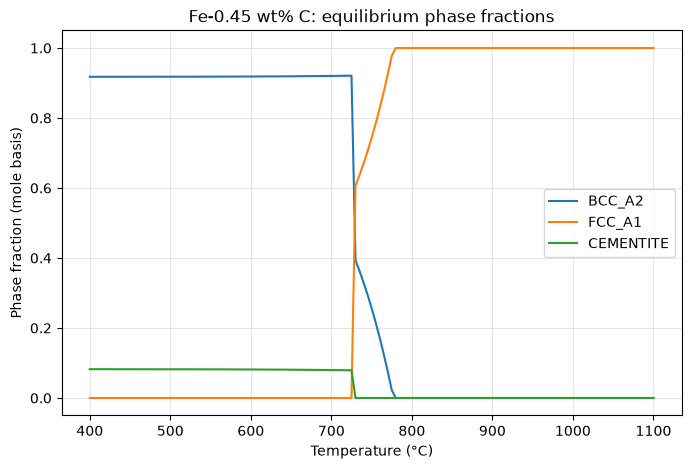

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pycalphad import equilibrium, variables as v

wt_c = 0.45
x = wtC_to_xC(wt_c)

comps = ['FE', 'C', 'VA']
phases = ['BCC_A2', 'FCC_A1', 'CEMENTITE'] #ferrite, austenite, cementite

#400 to 1140 degC, converted to Kelvin
eq = equilibrium(db, comps, phases,
                        {v.X('C'): x, v.T: (673.15, 1373.15, 5), v.P: 101325, v.N:1})

Ts = eq['T'].values
ph = eq.Phase.values.squeeze() #phases sitting at each vertex
npv = eq.NP.values.squeeze() #amount of each phase

fr = {p: np.zeros(len(Ts)) for p in phases}
for i in range(len(Ts)):
    for j in range(ph.shape[1]):
        name = ph[i, j]
        if name in fr and not np.isnan(npv[i, j]):
            fr[name][i] += npv[i, j]
            
#Critical temperatures (threshold 0.1% of a phase)
tol = 1e-3
A1 = Ts[fr['FCC_A1'] > tol].min()
A3 = Ts[(fr['BCC_A2'] < tol) & (Ts > A1)].min()
print(f"A1 = {A1 - 273.15:.0f} degC,  A3 = {A3 - 273.15:.0f} degC")

# Plot phase fractions against temperature in degC
fig, ax = plt.subplots(figsize=(8, 5))
for p in phases:
    ax.plot(Ts - 273.15, fr[p], label=p)
ax.set_xlabel('Temperature (°C)')
ax.set_ylabel('Phase fraction (mole basis)')
ax.set_title(f'Fe-{wt_c} wt% C: equilibrium phase fractions')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [8]:
def critical_temps(wt_c, step=2):
    x = wtC_to_xC(wt_c)
    comps = ['FE', 'C', 'VA']
    phases = ['BCC_A2', 'FCC_A1', 'CEMENTITE']
    eq = equilibrium(db, comps, phases,
                     {v.X('C'): x, v.T: (873.15, 1273.15, step),
                      v.P: 101325, v.N: 1})
    Ts = eq['T'].values
    ph = eq.Phase.values.squeeze()
    npv = eq.NP.values.squeeze()
    fr = {p: np.zeros(len(Ts)) for p in phases}
    for i in range(len(Ts)):
        for j in range(ph.shape[1]):
            if ph[i, j] in fr and not np.isnan(npv[i, j]):
                fr[ph[i, j]][i] += npv[i, j]
    tol = 1e-3
    A1 = Ts[fr['FCC_A1'] > tol].min() - 273.15
    A3 = Ts[(fr['BCC_A2'] < tol) & (Ts - 273.15 > A1)].min() - 273.15
    return A1, A3

import pandas as pd
rows = []
for c in [0.10, 0.20, 0.30, 0.45, 0.60]:
    A1, A3 = critical_temps(c)
    rows.append({'wt% C': c, 'A1 (°C)': round(A1), 'A3 (°C)': round(A3),
                 'Austenitise from (A3+30)': round(A3 + 30),
                 'to (A3+50)': round(A3 + 50)})
print(pd.DataFrame(rows))

   wt% C  A1 (°C)  A3 (°C)  Austenitise from (A3+30)  to (A3+50)
0   0.10      728      870                       900         920
1   0.20      728      838                       868         888
2   0.30      728      810                       840         860
3   0.45      728      778                       808         828
4   0.60      728      752                       782         802


In [9]:
#Starting the kinetics layer

MS_FORMULAS = {
    'andrews':       (539.0, {'C':423, 'Mn':30.4, 'Ni':17.7, 'Cr':12.1, 'Mo':7.5}),
    'steven_haynes': (561.0, {'C':474, 'Mn':33,   'Ni':17,   'Cr':17,   'Mo':21}),
    'kunitake':      (560.5, {'C':407.3, 'Si':7.3, 'Mn':37.8, 'Cu':20.5,
                              'Ni':19.5, 'Cr':19.8, 'Mo':4.5}),
}

def Ms(comp, method='andrews'):
    """Ms in degC. comp is a dict of wt%, e.g. {'C':0.45,'Mn':0.75}."""
    base, coeffs = MS_FORMULAS[method]
    ignored = [el for el, w in comp.items() if w > 0 and el not in coeffs]
    if ignored:
        print(f"Note: {method} has no term for {ignored}")
    return base - sum(k * comp.get(el, 0) for el, k in coeffs.items())

def Ms_all(comp):
    return {m: round(Ms(comp, m)) for m in MS_FORMULAS}

print(Ms_all({'C': 0.45}))
print(Ms_all({'C': 0.45, 'Mn': 0.75, 'Si': 0.25, 'Cu': 0.2}))   # illustrative steel

{'andrews': 349, 'steven_haynes': 348, 'kunitake': 377}
Note: andrews has no term for ['Si', 'Cu']
Note: steven_haynes has no term for ['Si', 'Cu']
{'andrews': 326, 'steven_haynes': 323, 'kunitake': 343}


0.984701
andrews: Ms=349 degC, martensite=0.972, retained austenite=0.028
steven_haynes: Ms=348 degC, martensite=0.971, retained austenite=0.029
kunitake: Ms=377 degC, martensite=0.979, retained austenite=0.021


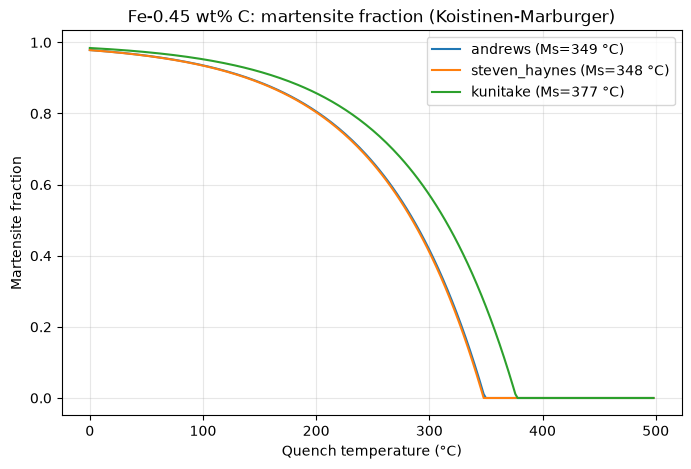

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def martensite_fraction(Ms, T, alpha=0.011):
    """Fraction of austenite transformed to martensite at temperature T (degC)."""
    return 0.0 if T >= Ms else 1 - np.exp(-alpha * (Ms - T))

# Test against the Cambridge program's worked example: Ms=400, T=20 -> 0.984701
print(round(martensite_fraction(400, 20), 6))

# Your 0.45 wt% C steel quenched to room temperature (25 degC)
for name, ms in Ms_all({'C': 0.45}).items():
    f = martensite_fraction(ms, 25)
    print(f"{name}: Ms={ms} degC, martensite={f:.3f}, retained austenite={1-f:.3f}")

# Curve of martensite fraction against quench temperature
fig, ax = plt.subplots(figsize=(8, 5))
T = np.arange(0, 500, 2)
for name, ms in Ms_all({'C': 0.45}).items():
    ax.plot(T, [martensite_fraction(ms, t) for t in T], label=f'{name} (Ms={ms} °C)')
ax.set_xlabel('Quench temperature (°C)')
ax.set_ylabel('Martensite fraction')
ax.set_title('Fe-0.45 wt% C: martensite fraction (Koistinen-Marburger)')
ax.legend(); ax.grid(alpha=0.3)
plt.show()